# 01 · Data audit and fixed splits (main section, 3 ft x 2 ft)

This notebook

1. loads `25280058_AI631_Project_Dataset.csv` (features $P_u$, $e_x$, $e_y$, target SAFE / UNSAFE),
2. audits it (balance, ranges, duplicates, the Bresler validity limit),
3. builds the **fixed test set**: 3000 stratified random points plus 1000 points from the band $|P_u/\phi P_{ni} - 1| \le 0.05$ around the true boundary,
4. draws **every training set of the protocol once** (sizes 20, 40, 80, 160, 320, seeds 0 to 4, and the three sampling strategies used in the ablation) from the remaining pool, and saves them to `results/3x2/splits/fixed_splits.json`.

Every later notebook reads that file, so every model trains on identical rows and is scored on the identical test set.
$\phi P_{ni}$ is used only to define the band and the sampling strategies. It is never a model input.

In [1]:
# Make the project helper package (qsvm_rc) importable from any sub-folder
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "qsvm_rc").is_dir() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print("Project root:", PROJECT_ROOT)

Project root: D:\LUMS PAs\3rd Semester\AI631 - Quantum Machine Learning\Project


In [2]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from qsvm_rc import config, data_utils, rc_capacity

SECTION = config.MAIN_SECTION

## 1. Load

In [3]:
frame = data_utils.load_section(SECTION)
print(f"Rows: {len(frame):,}")
print("Capacity source:", frame.attrs["capacity_source"])
print(f"Label agreement with r <= 1: {data_utils.label_agreement(frame):.5f}")
frame.head()

Rows: 170,660
Capacity source: extended column 'phi_Pni_kN'
Label agreement with r <= 1: 1.00000


,pu_kN,ex_mm,ey_mm,status,label,phi_pni_kN,ratio
0,1000,0.0,0.0,SAFE,1,13859.473,0.072153
1,1250,0.0,0.0,SAFE,1,13859.473,0.090191
2,1500,0.0,0.0,SAFE,1,13859.473,0.108229
3,1750,0.0,0.0,SAFE,1,13859.473,0.126267
4,2000,0.0,0.0,SAFE,1,13859.473,0.144306


## 2. Audit

In [4]:
print("Missing values per column:\n", frame.isna().sum(), "\n")
print("Duplicated (Pu, ex, ey) rows:", int(frame.duplicated(subset = config.FEATURE_COLUMNS).sum()))
print("\nClass balance:")
print(frame["status"].value_counts())
safe_fraction = np.mean(frame["label"] == 1)
print(f"SAFE fraction: {safe_fraction:.4f}  (majority class rate {max(safe_fraction, 1 - safe_fraction):.4f})")
print()
print(frame[config.FEATURE_COLUMNS + ["phi_pni_kN", "ratio"]].describe().T)

Missing values per column:
 pu_kN         0
ex_mm         0
ey_mm         0
status        0
label         0
phi_pni_kN    0
ratio         0
dtype: int64 

Duplicated (Pu, ex, ey) rows: 0

Class balance:
status
UNSAFE    116901
SAFE       53759
Name: count, dtype: int64
SAFE fraction: 0.3150  (majority class rate 0.6850)

               count         mean          std          min          25%  \
pu_kN       170660.0  7500.000000  3824.275840  1000.000000  4250.000000   
ex_mm       170660.0   264.428571   127.297951     0.000000   170.000000   
ey_mm       170660.0   174.456522    85.065622     0.000000   110.000000   
phi_pni_kN  170660.0  5048.477902  1632.039553  2954.447400  3909.323075   
ratio       170660.0     1.609230     0.941439     0.072153     0.829240   

                  50%           75%           max  
pu_kN       7500.0000  10750.000000  14000.000000  
ex_mm        282.5000    370.000000    455.000000  
ey_mm        187.5000    245.000000    300.000000  
phi_pni_kN  

In [5]:
for column in config.FEATURE_COLUMNS:
    values = np.sort(frame[column].unique())
    print(f"{column:<7} {len(values):>4} unique values, first {values[:6]}, last {values[-4:]}")

pu_kN     53 unique values, first [1000 1250 1500 1750 2000 2250], last [13250 13500 13750 14000]
ex_mm     70 unique values, first [ 0. 10. 20. 30. 40. 50.], last [440. 445. 450. 455.]
ey_mm     46 unique values, first [ 0. 10. 20. 30. 40. 50.], last [285. 290. 295. 300.]


In [6]:
# Bresler's method is valid for Pni >= 0.1 fc' Ag
constants = rc_capacity.section_constants(config.SECTIONS[SECTION])
pni = frame["phi_pni_kN"] / config.PHI
bresler_limit = constants["bresler_limit_kN"]
print(f"0.1 fc Ag = {bresler_limit:.1f} kN")
print(f"Rows with Pni below the limit: {int(np.sum(pni < bresler_limit))}")

0.1 fc Ag = 1672.3 kN
Rows with Pni below the limit: 0


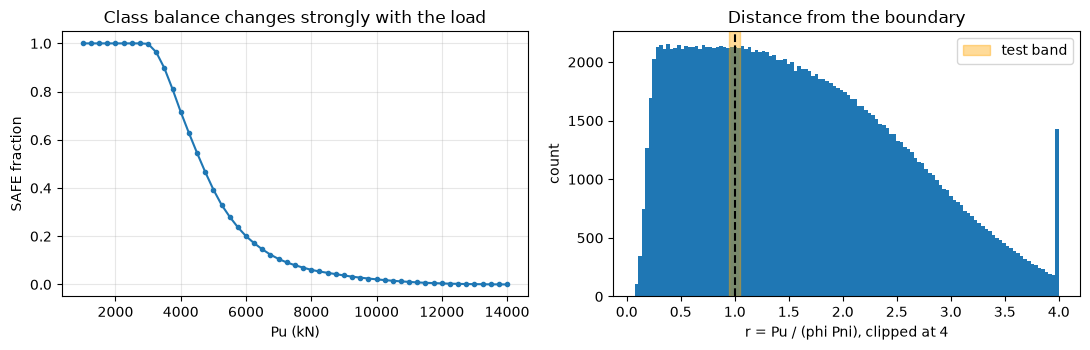

In [7]:
figure, axes = plt.subplots(1, 2, figsize = (11, 3.6))
safe_by_load = frame.groupby("pu_kN")["label"].apply(lambda labels: np.mean(labels == 1))
axes[0].plot(safe_by_load.index, safe_by_load.values, marker = ".")
axes[0].set_xlabel("Pu (kN)")
axes[0].set_ylabel("SAFE fraction")
axes[0].set_title("Class balance changes strongly with the load")
axes[0].grid(alpha = 0.3)

axes[1].hist(np.clip(frame["ratio"], 0, 4), bins = 120, color = "tab:blue")
axes[1].axvline(1, color = "k", linestyle = "--")
axes[1].axvspan(1 - config.TEST_BAND_HALF_WIDTH, 1 + config.TEST_BAND_HALF_WIDTH, color = "orange", alpha = 0.4, label = "test band")
axes[1].set_xlabel("r = Pu / (phi Pni), clipped at 4")
axes[1].set_ylabel("count")
axes[1].legend()
axes[1].set_title("Distance from the boundary")
figure.tight_layout()
figure.savefig(config.figures_dir() / "data_balance_and_ratio.png", dpi = 200)
plt.show()

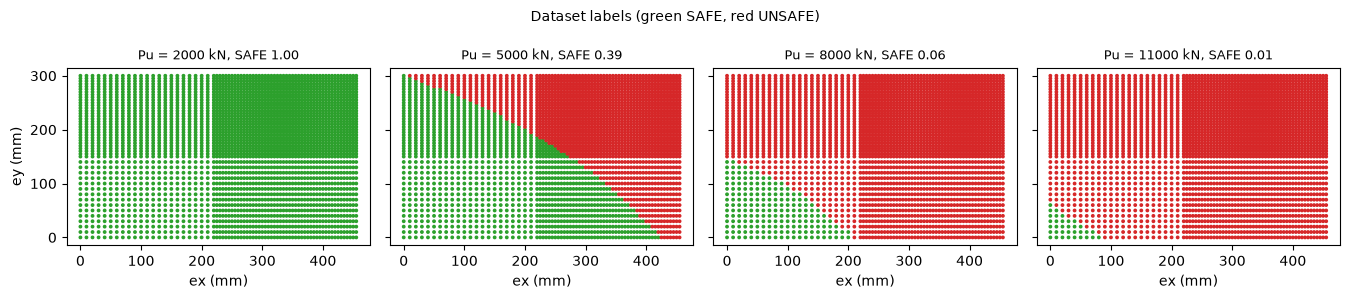

In [8]:
# The true SAFE region in the ex-ey plane at a few loads, straight from the dataset
load_levels = [2000, 5000, 8000, 11000]
available = np.sort(frame["pu_kN"].unique())
load_levels = [float(available[np.argmin(np.abs(available - level))]) for level in load_levels]

figure, axes = plt.subplots(1, len(load_levels), figsize = (3.4 * len(load_levels), 3), sharey = True)
for axis, level in zip(axes, load_levels):
    rows = frame[frame["pu_kN"] == level]
    axis.scatter(rows["ex_mm"], rows["ey_mm"], c = np.where(rows["label"] == 1, "tab:green", "tab:red"), s = 3)
    safe_share = np.mean(rows["label"] == 1)
    axis.set_title(f"Pu = {level:.0f} kN, SAFE {safe_share:.2f}", fontsize = 9)
    axis.set_xlabel("ex (mm)")
axes[0].set_ylabel("ey (mm)")
figure.suptitle("Dataset labels (green SAFE, red UNSAFE)", fontsize = 10)
figure.tight_layout()
figure.savefig(config.figures_dir() / "data_true_regions.png", dpi = 200)
plt.show()

## 3. Fixed test set and all training sets

* Test band: 1000 points with $|r - 1| \le 0.05$. The boundary error on these points is the main metric.
* Test random: 3000 points, stratified, drawn from everything outside the band sample.
* Pool: everything not in the test set. Training sets come only from here.
* Sampling strategies (ablation): `random` (stratified from the pool), `boundary` (stratified from the pool points with $|r - 1| \le 0.2$), `mixed` (half and half).
  All three keep the overall SAFE fraction, so they differ only in where the points lie.

In [9]:
splits = data_utils.make_fixed_splits(frame, SECTION)
split_path = data_utils.save_splits(splits)
print("Saved:", split_path)
test_random_count = len(splits["test_random"])
test_band_count = len(splits["test_band"])
pool_count = splits["pool_size"]
pool_band_count = splits["pool_band_size"]
print(f"Test random: {test_random_count}   test band: {test_band_count}")
print(f"Pool: {pool_count:,}   pool points inside |r - 1| <= {config.TRAIN_BAND_HALF_WIDTH}: {pool_band_count:,}")
print("Training sets saved:", len(splits["training_sets"]))

Saved: D:\LUMS PAs\3rd Semester\AI631 - Quantum Machine Learning\Project\results\3x2\splits\fixed_splits.json
Test random: 3000   test band: 1000
Pool: 166,660   pool points inside |r - 1| <= 0.2: 24,548
Training sets saved: 75


In [10]:
# Checks: no training row is a test row, sizes and class balance are right, band rows really are in the band
test_rows, band_mask = data_utils.test_indices(splits)
test_set = set(test_rows.tolist())
labels = frame["label"].to_numpy()
ratio = frame["ratio"].to_numpy()

problems = 0
for key, rows in splits["training_sets"].items():
    strategy, size, train_seed = key.split("|")
    if len(rows) != int(size) or test_set.intersection(rows):
        problems = problems + 1
print("Training sets overlapping the test set or with the wrong size:", problems)
print("Band rows outside the band:", int(np.sum(np.abs(ratio[test_rows[band_mask]] - 1) > config.TEST_BAND_HALF_WIDTH + 1e-9)))
print(f"SAFE fraction  test random {np.mean(labels[test_rows[np.logical_not(band_mask)]] == 1):.3f}   "
      f"test band {np.mean(labels[test_rows[band_mask]] == 1):.3f}")
for strategy in config.SAMPLING_STRATEGIES:
    example = data_utils.training_indices(splits, 160, 0, strategy)
    print(f"{strategy:<9} n=160 seed=0: SAFE {np.mean(labels[example] == 1):.3f}, "
          f"median |r - 1| {np.median(np.abs(ratio[example] - 1)):.3f}")
print("PASS" if problems == 0 else "FAIL")

Training sets overlapping the test set or with the wrong size: 0
Band rows outside the band: 0
SAFE fraction  test random 0.315   test band 0.489
random    n=160 seed=0: SAFE 0.312, median |r - 1| 0.765
boundary  n=160 seed=0: SAFE 0.312, median |r - 1| 0.093
mixed     n=160 seed=0: SAFE 0.312, median |r - 1| 0.180
PASS


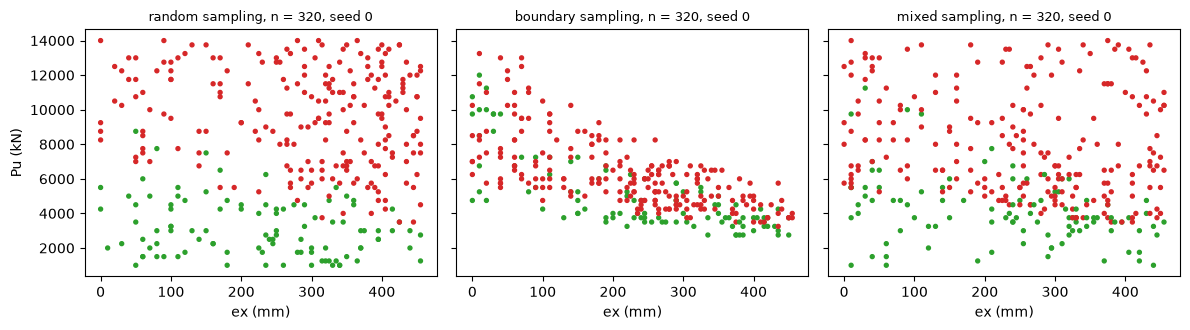

In [11]:
figure, axes = plt.subplots(1, 3, figsize = (12, 3.4), sharey = True)
examples = {strategy: data_utils.training_indices(splits, 320, 0, strategy) for strategy in config.SAMPLING_STRATEGIES}
for axis, (strategy, rows) in zip(axes, examples.items()):
    chosen = frame.iloc[rows]
    axis.scatter(chosen["ex_mm"], chosen["pu_kN"], c = np.where(chosen["label"] == 1, "tab:green", "tab:red"), s = 8)
    axis.set_title(f"{strategy} sampling, n = 320, seed 0", fontsize = 9)
    axis.set_xlabel("ex (mm)")
axes[0].set_ylabel("Pu (kN)")
figure.tight_layout()
figure.savefig(config.figures_dir() / "data_sampling_strategies.png", dpi = 200)
plt.show()

In [12]:
summary = {
    "rows": int(len(frame)),
    "safe_fraction": float(np.mean(labels == 1)),
    "capacity_source": frame.attrs["capacity_source"],
    "label_agreement": data_utils.label_agreement(frame),
    "test_random": len(splits["test_random"]),
    "test_band": len(splits["test_band"]),
    "pool": splits["pool_size"],
    "scaler": data_utils.domain_scaler(SECTION, frame).to_dict(),
}
with open(config.section_results_dir(SECTION, "splits") / "dataset_summary.json", "w") as handle:
    json.dump(summary, handle, indent = 2)
summary

{'rows': 170660,
 'safe_fraction': 0.31500644556427987,
 'capacity_source': "extended column 'phi_Pni_kN'",
 'label_agreement': 1.0,
 'test_random': 3000,
 'test_band': 1000,
 'pool': 166660,
 'scaler': {'lower_bounds': [1000.0, 0.0, 0.0],
  'upper_bounds': [14000.0, 457.2, 304.8]}}

Next: `01_data/02_extra_sections_generation.ipynb` (only needed for the section ablation), or go straight to `02_classical/01_classical_baselines.ipynb`.